# 05. Đánh giá mô hình dự báo chuỗi thời gian (Model Evaluation)
Notebook này thực hiện:
1. Nạp tập dữ liệu kiểm thử (Test Set: 24,249 dòng, 24 đặc trưng) và model XGBoost đã huấn luyện.
2. Dự báo trên tập Train và tập Test.
3. Đo lường các chỉ số MAE, RMSE, MAPE, R2-score.
4. Trực quan hóa kết quả dự báo (Actual vs Predicted) và phân tích phần dư (Residuals).

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cài đặt style cho đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)

In [2]:
import os
import joblib
import pandas as pd

# Đường dẫn thư mục
PROCESSED_DATA_PATH = "../DATA/processed"
MODEL_PATH = "../models"

# 1. Đọc dữ liệu từ thư mục DATA/processed (file CSV)
X_train = pd.read_csv(f"{PROCESSED_DATA_PATH}/X_train.csv", index_col=0)
X_test = pd.read_csv(f"{PROCESSED_DATA_PATH}/X_test.csv", index_col=0)
y_train = pd.read_csv(f"{PROCESSED_DATA_PATH}/y_train.csv", index_col=0).squeeze()
y_test = pd.read_csv(f"{PROCESSED_DATA_PATH}/y_test.csv", index_col=0).squeeze()

# 2. Tải mô hình đã lưu
model = joblib.load(f"{MODEL_PATH}/xgboost_model.pkl")

print("Dữ liệu và mô hình đã được tải thành công!")
print(f"Kích thước X_test: {X_test.shape}")
print(f"Kích thước y_test: {y_test.shape}")

Dữ liệu và mô hình đã được tải thành công!
Kích thước X_test: (24249, 24)
Kích thước y_test: (24249,)


In [3]:
# Dự báo trên cả 2 tập để đối chiếu Overfitting
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Chuyển đổi về Series giữ nguyên index thời gian để tiện vẽ biểu đồ
y_test_pred_series = pd.Series(y_test_pred, index=y_test.index, name="Predicted")

In [4]:
def calculate_metrics(y_true, y_pred, set_name="Test Set"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    # Tránh chia cho 0 khi tính MAPE
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-6, y_true))) * 100
    r2 = r2_score(y_true, y_pred)
    
    return {
        "Dataset": set_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "MAPE (%)": round(mape, 2),
        "R2 Score": round(r2, 4)
    }

# Tính toán chỉ số cho cả hai tập
metrics_train = calculate_metrics(y_train, y_train_pred, "Train Set")
metrics_test = calculate_metrics(y_test, y_test_pred, "Test Set")

# Tổng hợp bảng so sánh để điền vào 05_evaluation.md
df_metrics = pd.DataFrame([metrics_train, metrics_test])
display(df_metrics)

,Dataset,MAE,RMSE,MAPE (%),R2 Score
0,Train Set,140.6684,188.1401,0.90,0.9947
1,Test Set,149.9682,202.9734,1.04,0.9931


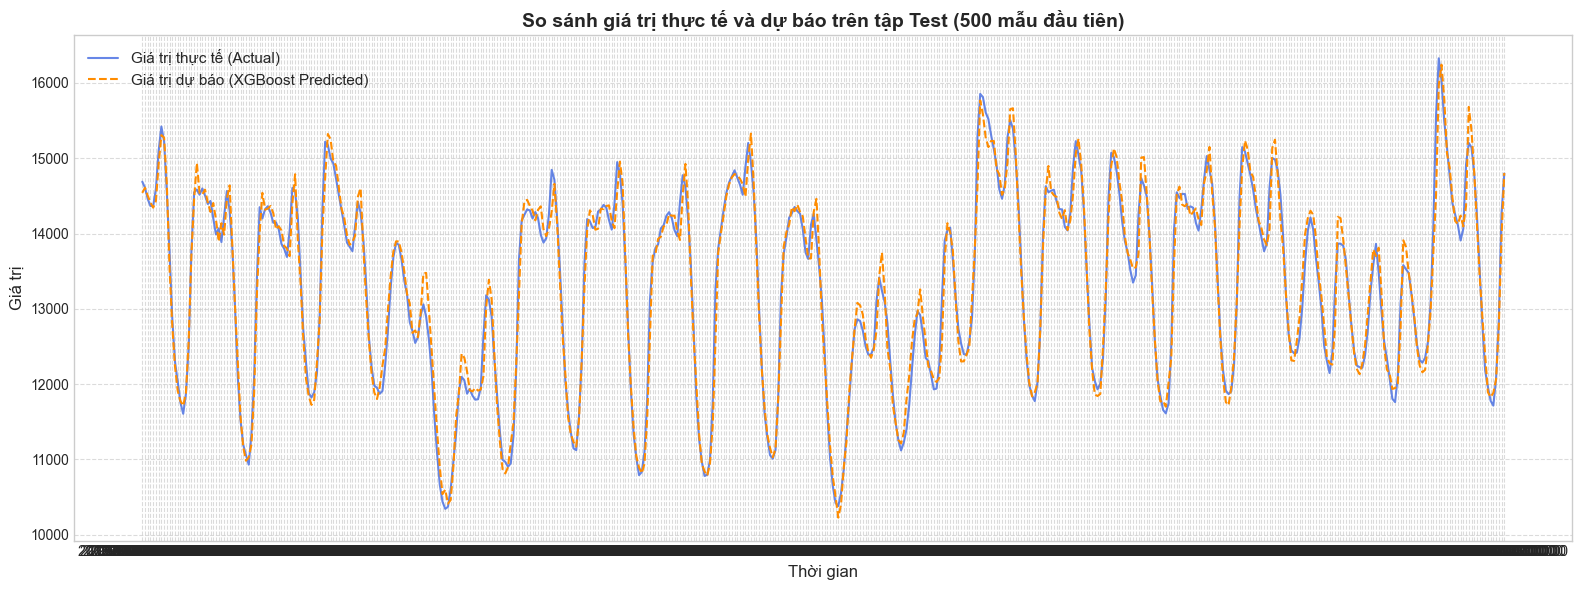

In [5]:
plt.figure(figsize=(16, 6))

# Lấy một khoảng thời gian cụ thể (ví dụ 500 mẫu đầu của Test Set để nhìn rõ đường nét)
SAMPLE_RANGE = 500  

plt.plot(y_test.index[:SAMPLE_RANGE], y_test.iloc[:SAMPLE_RANGE], label="Giá trị thực tế (Actual)", color="royalblue", alpha=0.8, linewidth=1.5)
plt.plot(y_test.index[:SAMPLE_RANGE], y_test_pred_series.iloc[:SAMPLE_RANGE], label="Giá trị dự báo (XGBoost Predicted)", color="darkorange", linestyle="--", linewidth=1.5)

plt.title(f"So sánh giá trị thực tế và dự báo trên tập Test ({SAMPLE_RANGE} mẫu đầu tiên)", fontsize=14, fontweight="bold")
plt.xlabel("Thời gian", fontsize=12)
plt.ylabel("Giá trị", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()

# Lưu biểu đồ để chèn vào docs/reports
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/actual_vs_predicted.png", dpi=300)
plt.show()

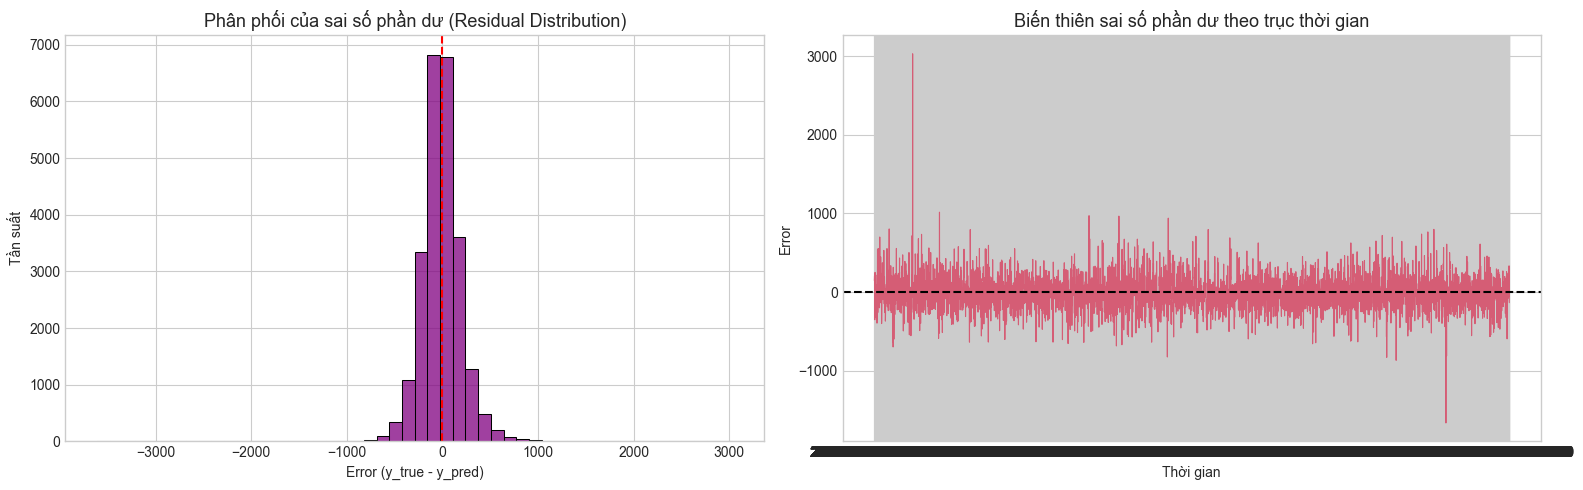

In [6]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Tắt kde=True hoặc chỉ lấy mẫu để vẽ KDE siêu tốc
sns.histplot(residuals, kde=False, ax=axes[0], color="purple", bins=50)
axes[0].set_title("Phân phối của sai số phần dư (Residual Distribution)", fontsize=13)
axes[0].set_xlabel("Error (y_true - y_pred)")
axes[0].set_ylabel("Tần suất")
axes[0].axvline(x=0, color="red", linestyle="--")

# 2. Giảm bớt số điểm vẽ biểu đồ thời gian (downsample hoặc lấy 1000-2000 điểm tiêu biểu)
# Hoặc vẽ nhanh bằng plot thông thường
axes[1].plot(y_test.index[::5], residuals[::5], color="crimson", alpha=0.6, linewidth=0.8)
axes[1].axhline(y=0, color="black", linestyle="--")
axes[1].set_title("Biến thiên sai số phần dư theo trục thời gian", fontsize=13)
axes[1].set_xlabel("Thời gian")
axes[1].set_ylabel("Error")

plt.tight_layout()

# Giảm dpi xuống 120-150 (đủ nét cho báo cáo/markdown và lưu rất nhanh)
plt.savefig("../reports/figures/residual_analysis.png", dpi=150)
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9920\2673361658.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importance.head(15), y=feature_importance.head(15).index, palette="viridis")


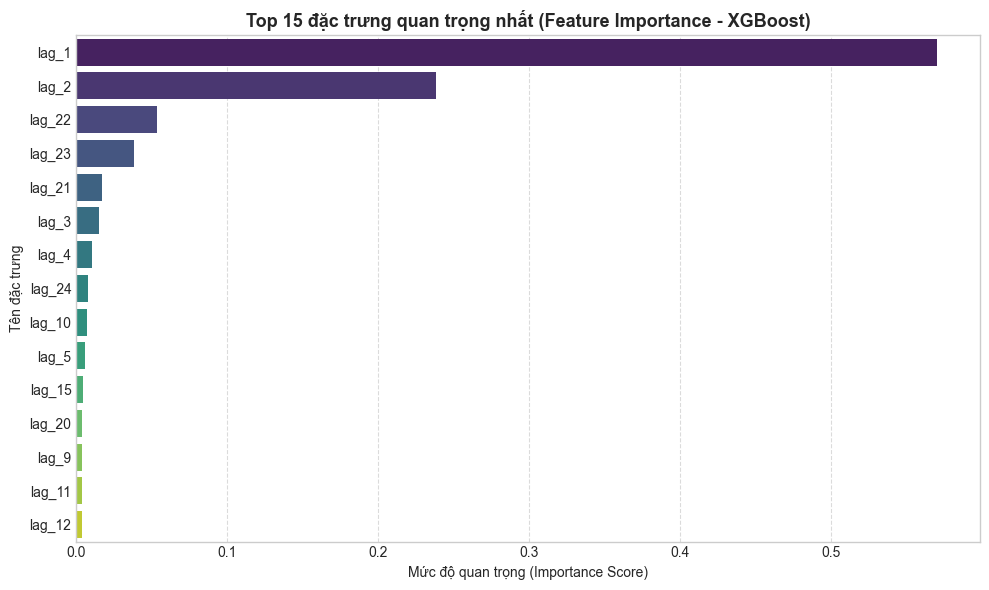

In [7]:
# Lấy top 15 đặc trưng ảnh hưởng nhiều nhất đến quyết định của cây XGBoost
feature_importance = pd.Series(model.feature_importances_, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance.head(15), y=feature_importance.head(15).index, palette="viridis")
plt.title("Top 15 đặc trưng quan trọng nhất (Feature Importance - XGBoost)", fontsize=13, fontweight="bold")
plt.xlabel("Mức độ quan trọng (Importance Score)")
plt.ylabel("Tên đặc trưng")
plt.grid(axis='x', linestyle="--", alpha=0.7)
plt.tight_layout()

plt.savefig("../reports/figures/feature_importance.png", dpi=300)
plt.show()